In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [4]:
data_path = Path.home() / "VoltAhead" / "data" / "UrbanEVDataset" / "20220901-20230228_station-raw" / "charge_5min"

print(data_path.exists())

True


In [5]:
station_files = sorted(data_path.glob("*.csv"))

print("Number of station files:", len(station_files))
print("First 5 files:", station_files[:5])

Number of station files: 1682
First 5 files: [PosixPath('/Users/nehiraydemir/VoltAhead/data/UrbanEVDataset/20220901-20230228_station-raw/charge_5min/1001.csv'), PosixPath('/Users/nehiraydemir/VoltAhead/data/UrbanEVDataset/20220901-20230228_station-raw/charge_5min/1002.csv'), PosixPath('/Users/nehiraydemir/VoltAhead/data/UrbanEVDataset/20220901-20230228_station-raw/charge_5min/1003.csv'), PosixPath('/Users/nehiraydemir/VoltAhead/data/UrbanEVDataset/20220901-20230228_station-raw/charge_5min/1004.csv'), PosixPath('/Users/nehiraydemir/VoltAhead/data/UrbanEVDataset/20220901-20230228_station-raw/charge_5min/1005.csv')]


In [6]:
df = pd.read_csv(station_files[0])

df.head()

,time,busy,idle,s_price,e_price,fast_busy,fast_idle,slow_busy,slow_idle,duration,volume
0,2022-09-01 00:00:00,4.0,16.0,0.47,1.2,0.0,0.0,4.0,16.0,0.000000,0.000000
1,2022-09-01 00:05:00,4.0,16.0,0.47,1.2,0.0,0.0,4.0,16.0,0.000000,0.000000
2,2022-09-01 00:10:00,4.0,16.0,0.47,1.2,0.0,0.0,4.0,16.0,0.000000,0.000000
3,2022-09-01 00:15:00,8.0,12.0,0.47,1.2,0.0,0.0,8.0,12.0,0.083333,0.583333
4,2022-09-01 00:20:00,6.0,14.0,0.47,1.2,0.0,0.0,6.0,14.0,0.083333,0.583333


In [7]:
print("Station ID:", station_files[0].stem)
print("Number of observations:", len(df))
print("Columns:", df.columns.tolist())

df.info()

Station ID: 1001
Number of observations: 52128
Columns: ['time', 'busy', 'idle', 's_price', 'e_price', 'fast_busy', 'fast_idle', 'slow_busy', 'slow_idle', 'duration', 'volume']
<class 'pandas.DataFrame'>
RangeIndex: 52128 entries, 0 to 52127
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   time       52128 non-null  str    
 1   busy       41444 non-null  float64
 2   idle       41444 non-null  float64
 3   s_price    41444 non-null  float64
 4   e_price    41444 non-null  float64
 5   fast_busy  41444 non-null  float64
 6   fast_idle  41444 non-null  float64
 7   slow_busy  41444 non-null  float64
 8   slow_idle  41444 non-null  float64
 9   duration   41444 non-null  float64
 10  volume     41444 non-null  float64
dtypes: float64(10), str(1)
memory usage: 5.3 MB


## Consecutive Observation Analysis

The objective of this analysis is to investigate how
frequently charging point availability remains unchanged
between consecutive five-minute observations.

Missing observations are excluded from the comparison
to avoid misleading results.

In [8]:
df["time"] = pd.to_datetime(df["time"])

df = df.sort_values("time").reset_index(drop=True)

df[["time", "idle", "busy"]].head()


,time,idle,busy
0,2022-09-01 00:00:00,16.0,4.0
1,2022-09-01 00:05:00,16.0,4.0
2,2022-09-01 00:10:00,16.0,4.0
3,2022-09-01 00:15:00,12.0,8.0
4,2022-09-01 00:20:00,14.0,6.0


In [9]:
df["previous_idle"] = df["idle"].shift(1)

df["time_difference"] = df["time"].diff()

df[["time", "idle", "previous_idle", "time_difference"]].head()

,time,idle,previous_idle,time_difference
0,2022-09-01 00:00:00,16.0,NaN,NaT
1,2022-09-01 00:05:00,16.0,16.0,0 days 00:05:00
2,2022-09-01 00:10:00,16.0,16.0,0 days 00:05:00
3,2022-09-01 00:15:00,12.0,16.0,0 days 00:05:00
4,2022-09-01 00:20:00,14.0,12.0,0 days 00:05:00


In [10]:
valid_pairs = df[
    df["idle"].notna()
    & df["previous_idle"].notna()
    & (df["time_difference"] == pd.Timedelta(minutes=5))
].copy()

unchanged = (
    valid_pairs["idle"] == valid_pairs["previous_idle"]
)

unchanged_rate = unchanged.mean() * 100

print("Valid observation pairs:", len(valid_pairs))
print(f"Unchanged occupancy rate: {unchanged_rate:.2f}%")
print(f"Changed occupancy rate: {100 - unchanged_rate:.2f}%")

Valid observation pairs: 41435
Unchanged occupancy rate: 76.06%
Changed occupancy rate: 23.94%


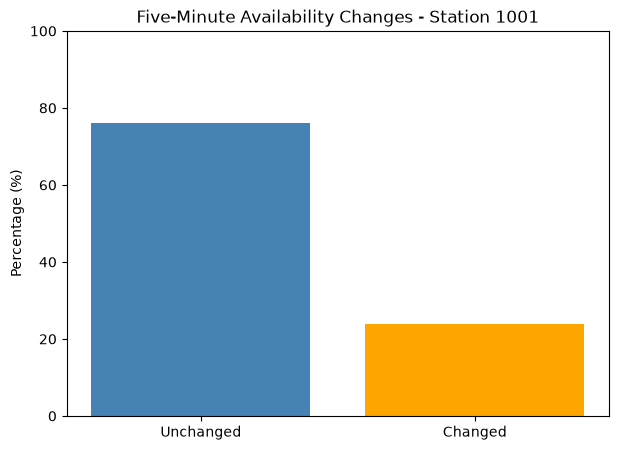

In [11]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["Unchanged", "Changed"],
    [unchanged_rate, 100 - unchanged_rate],
    color=["steelblue", "orange"]
)

plt.ylabel("Percentage (%)")
plt.title("Five-Minute Availability Changes - Station 1001")
plt.ylim(0, 100)

plt.show()

In [12]:
valid_pairs["available_now"] = (
    valid_pairs["idle"] > 0
).astype(int)

valid_pairs["available_previous"] = (
    valid_pairs["previous_idle"] > 0
).astype(int)

status_unchanged_rate = (
    valid_pairs["available_now"]
    == valid_pairs["available_previous"]
).mean() * 100

print(f"Availability status unchanged: {status_unchanged_rate:.2f}%")
print(f"Availability status changed: {100 - status_unchanged_rate:.2f}%")

Availability status unchanged: 84.36%
Availability status changed: 15.64%


In [13]:
print(f"Idle count stability: {unchanged_rate:.2f}%")
print(f"Availability status stability: {status_unchanged_rate:.2f}%")

Idle count stability: 76.06%
Availability status stability: 84.36%


### Preliminary Findings – Station 1001

- The number of available charging points remains
  unchanged in 76.06% of valid consecutive observations.

- The binary availability status remains unchanged
  in 84.36% of valid consecutive observations.

- These findings suggest short-term temporal stability
  in charging station availability.

- Further analysis is required to determine whether
  this relationship persists over longer prediction
  horizons and across other stations.

## Temporal Autocorrelation Analysis

This analysis measures the correlation between
charging point availability at different time lags.

The objective is to investigate how informative
historical occupancy values are for future
availability predictions.